# CNC Guard — 2. Fasea: Aurreprozesatzea eta Entrenamendua

**AABD Espezializazioa · 5071, 5072, 5073 moduluak**

Helburua: `ai4i2020_train.csv` datuetatik hutsegiteak iragarriko dituen eredu bat entrenatu eta `models/cnc_failure_model.pkl` gisa gorde.

## 1. Liburutegiak eta Karga

Beharrezko liburutegiak inportatu eta datuak kargatu.

In [2]:
from IPython.core.display_functions import display
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    PrecisionRecallDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split

# Csv-a kargatu
df = pd.read_csv('../data/ai4i2020_train.csv')

# Lehenengo lerroak
print("\n--- Lehenengo lerroak ---")
display(df.head())

print("\n--- Datasetaren informazioa ---")
df.info()

print("\n--- Estatistikaren deskribapena ---")
display(df.describe())

print("\n--- Balore nuloak ---")
print(df.isnull().sum())

print("\n--- Helburu-aldagaiaren (machine_failure) banaketa (%) ---")
print(df["machine_failure"].value_counts(normalize=True) * 100)


--- Lehenengo lerroak ---


,machine_id,machine_type,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_failure,failure_TWF,failure_HDF,failure_PWF,failure_OSF,failure_RNF
0,CNC-024,M,302.0,310.9,1456,47.2,54,0,0,0,0,0,0
1,CNC-011,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
2,CNC-030,M,301.0,311.6,1357,45.6,137,0,0,0,0,0,0
3,CNC-050,L,298.9,309.8,1411,56.3,84,0,0,0,0,0,0
4,CNC-040,L,297.1,308.5,1733,28.7,50,0,0,0,0,0,0



--- Datasetaren informazioa ---
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   machine_id       8000 non-null   str    
 1   machine_type     8000 non-null   str    
 2   air_temp_K       8000 non-null   float64
 3   process_temp_K   8000 non-null   float64
 4   rpm              8000 non-null   int64  
 5   torque_Nm        8000 non-null   float64
 6   tool_wear_min    8000 non-null   int64  
 7   machine_failure  8000 non-null   int64  
 8   failure_TWF      8000 non-null   int64  
 9   failure_HDF      8000 non-null   int64  
 10  failure_PWF      8000 non-null   int64  
 11  failure_OSF      8000 non-null   int64  
 12  failure_RNF      8000 non-null   int64  
dtypes: float64(3), int64(8), str(2)
memory usage: 812.6 KB

--- Estatistikaren deskribapena ---


,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_failure,failure_TWF,failure_HDF,failure_PWF,failure_OSF,failure_RNF
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000
mean,300.005450,310.006062,1539.356875,40.003363,107.685000,0.033875,0.004500,0.01075,0.010250,0.010250,0.001875
std,1.996844,1.479432,180.982943,10.019546,63.612002,0.180919,0.066935,0.10313,0.100728,0.100728,0.043263
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,298.300000,308.800000,1422.000000,33.200000,53.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,107.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,301.500000,311.100000,1613.000000,46.800000,163.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000



--- Balore nuloak ---
machine_id         0
machine_type       0
air_temp_K         0
process_temp_K     0
rpm                0
torque_Nm          0
tool_wear_min      0
machine_failure    0
failure_TWF        0
failure_HDF        0
failure_PWF        0
failure_OSF        0
failure_RNF        0
dtype: int64

--- Helburu-aldagaiaren (machine_failure) banaketa (%) ---
machine_failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64


## 2. EDA — Datu-azterketa

Aztertu: zutabe motak eta balioen barrutiak, datu-balioen banaketa, korrelazioak


--- Sentsore-balioen tarteak ---


,min,mean,max,std
air_temp_K,295.3,300.005450,304.5,1.996844
process_temp_K,305.7,310.006062,313.8,1.479432
rpm,1168.0,1539.356875,2886.0,180.982943
torque_Nm,3.8,40.003363,76.6,10.019546
tool_wear_min,0.0,107.685000,253.0,63.612002


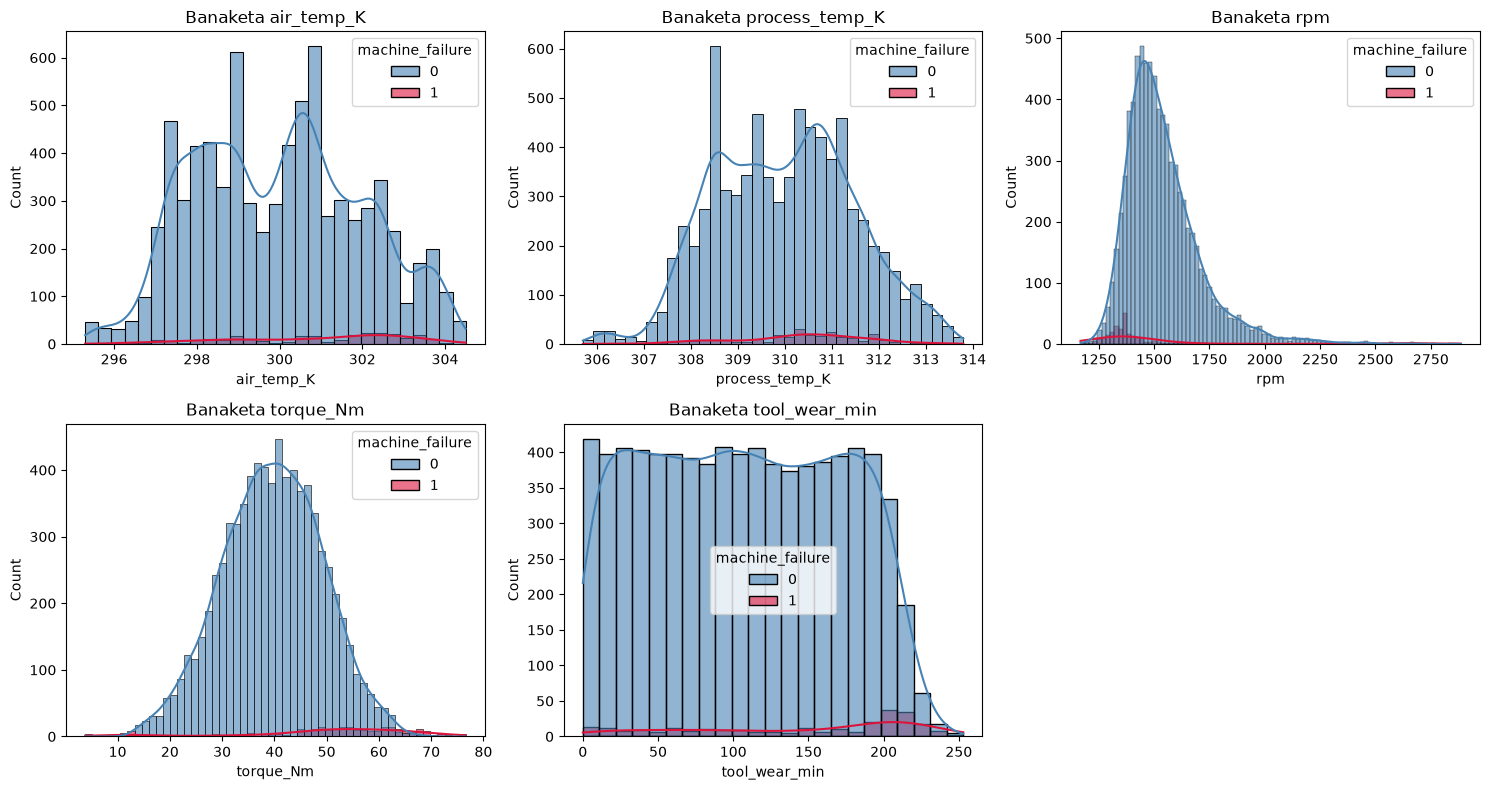

--- Helburu-aldagaiaren zenbaketak ---
0 (Normal): 7729 makina (96.61%)
1 (Fallo):  271 makina (3.39%)


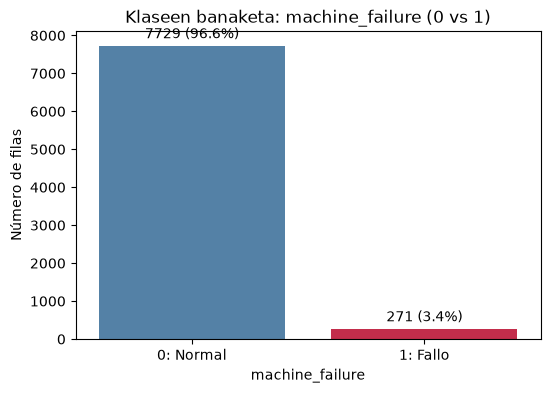


--- Huts-mota zehatzaren araberako kontaketa ---
failure_TWF    36
failure_HDF    86
failure_PWF    82
failure_OSF    82
failure_RNF    15
dtype: int64


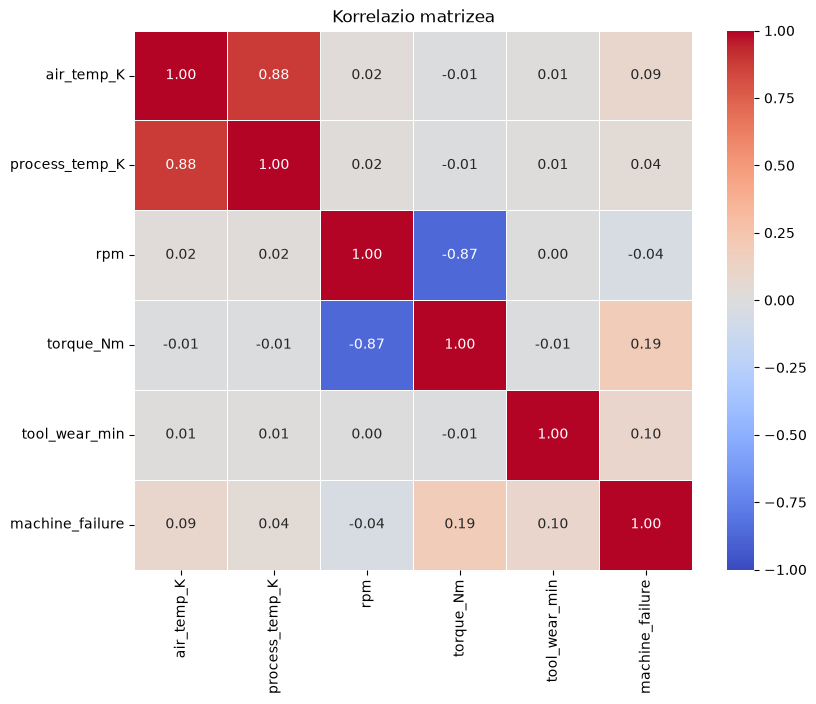


--- Machine_failure-rekiko korrelazio zuzena ---
machine_failure    1.000000
torque_Nm          0.190034
tool_wear_min      0.099214
air_temp_K         0.086001
process_temp_K     0.040849
rpm               -0.039966
Name: machine_failure, dtype: float64


In [5]:
# 2.1. Sentsore numerikoentzako balio-tarteak
sensor_cols = [
    "air_temp_K",
    "process_temp_K",
    "rpm",
    "torque_Nm",
    "tool_wear_min",
]

print("--- Sentsore-balioen tarteak ---")
display(df[sensor_cols].describe().T[["min", "mean", "max", "std"]])

# Sentsoreen banaketa-grafikoak, hutsegite-motaren arabera
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
  sns.histplot(
      data=df,
      x=col,
      hue="machine_failure",
      kde=True,
      ax=axes[i],
      palette={0: "steelblue", 1: "crimson"},
      alpha=0.6,
  )
  axes[i].set_title(f"Banaketa {col}")

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

# 2.2. Klase-desorekaren zenbaketa grafikoa
counts = df["machine_failure"].value_counts()
percentages = df["machine_failure"].value_counts(normalize=True) * 100

print("--- Helburu-aldagaiaren zenbaketak ---")
print(f"0 (Normal): {counts[0]} makina ({percentages[0]:.2f}%)")
print(f"1 (Fallo):  {counts[1]} makina ({percentages[1]:.2f}%)")

plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    palette=["steelblue", "crimson"],
    legend=False,
)
plt.title("Klaseen banaketa: machine_failure (0 vs 1)")
plt.xlabel("machine_failure")
plt.ylabel("Número de filas")
plt.xticks([0, 1], ["0: Normal", "1: Fallo"])

for p in ax.patches:
  ax.annotate(
      f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontsize=10,
      xytext=(0, 3),
      textcoords="offset points",
  )
plt.show()

# Huts-mota zehatzaren araberako kontaketa
failure_cols = [
    "failure_TWF",
    "failure_HDF",
    "failure_PWF",
    "failure_OSF",
    "failure_RNF",
]
print("\n--- Huts-mota zehatzaren araberako kontaketa ---")
print(df[failure_cols].sum())

# 2.3. Korrelazio matrizea
plt.figure(figsize=(9, 7))
corr_matrix = df[sensor_cols + ["machine_failure"]].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Korrelazio matrizea")
plt.show()

print("\n--- Machine_failure-rekiko korrelazio zuzena ---")
print(corr_matrix["machine_failure"].sort_values(ascending=False))

## 3. Aurreprozesatzea

Prestatu datuak entrenamendurako, feature engineering...

In [6]:
# 1. Nahi ez diren zutabeak kentzea / data leakage
drop_cols = [
    "machine_id",
    "failure_TWF",
    "failure_HDF",
    "failure_PWF",
    "failure_OSF",
    "failure_RNF",
]
df_clean = df.drop(columns=drop_cols)

# 2. machine_type-rako one-hot kodetzea
df_encoded = pd.get_dummies(df_clean, columns=["machine_type"], drop_first=True)

# 3. FEATURE ENGINEERING
df_encoded["power"] = df_encoded["rpm"] * df_encoded["torque_Nm"]
df_encoded["temp_diff"] = (
    df_encoded["process_temp_K"] - df_encoded["air_temp_K"]
)
df_encoded["torque_wear"] = (
    df_encoded["torque_Nm"] * df_encoded["tool_wear_min"]
)

# 4. Ezaugarrien (X) eta helburu-aldagaiaren (y) bereizketa
X = df_encoded.drop(columns=["machine_failure"])
y = df_encoded["machine_failure"]

print(f"X-ren dimentsio berriak: {X.shape}")

X-ren dimentsio berriak: (8000, 10)


## 4. Train / Validation Zatiketa

In [16]:
# Espero diren sentsore-ezaugarrien definizio esplizitua
FEATURES = ["air_temp_K", "process_temp_K", "rpm", "torque_Nm", "tool_wear_min"]

# Entrenamendu-multzoan (% 80) eta balidazio-multzoan (% 20) banatu
# stratify=y aukerak bi zatietan mantentzen du porrot-proportzioa
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Entrenamendu-multzoa (X_train): {X_train.shape[0]} errenkada")
print(f"Balidazio-multzoa (X_val): {X_val.shape[0]} errenkada")

print("\n--- Klaseen banaketa X_train-en (%) ---")
print(y_train.value_counts(normalize=True) * 100)

Entrenamendu-multzoa (X_train): 6400 errenkada
Balidazio-multzoa (X_val): 1600 errenkada

--- Klaseen banaketa X_train-en (%) ---
machine_failure
0    96.609375
1     3.390625
Name: proportion, dtype: float64


## 5. Entrenamendua

Eredu bat (gutxienez) entrenatu. Aukerakoa: hainbat eredu konparatu.

In [8]:
model = RandomForestClassifier(
    n_estimators=2000,
    max_depth=15,
    min_samples_split=4,
    class_weight="balanced",
    random_state=42,
)
model.fit(X_train, y_train)

print("Ezaugarri-ingeniaritza erabiliz entrenatutako eredua.")

Ezaugarri-ingeniaritza erabiliz entrenatutako eredua.


## 6. Ebaluazioa

Ebaluatu metrika desberdinekin.

--- Hasierako Sailkapen Txostena (Umbral 0.35) ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1546
           1       0.88      0.80      0.83        54

    accuracy                           0.99      1600
   macro avg       0.94      0.90      0.91      1600
weighted avg       0.99      0.99      0.99      1600



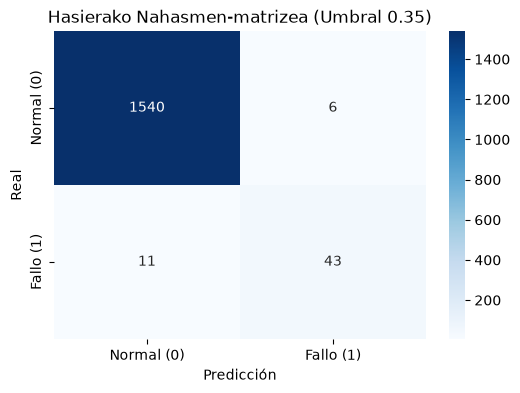

ROC AUC Score: 0.9819


In [10]:
# 1. Atalasea duten iragarpenak
y_prob = model.predict_proba(X_val)[:, 1]
y_pred = (y_prob >= 0.35).astype(int)

print("--- Hasierako Sailkapen Txostena (Umbral 0.35) ---")
print(classification_report(y_val, y_pred))

# 2. Hasierako Nahasmen-matrizea (Ajustatu gabe)
cm_inicial = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_inicial,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal (0)", "Fallo (1)"],
    yticklabels=["Normal (0)", "Fallo (1)"],
)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Hasierako Nahasmen-matrizea (Umbral 0.35)")
plt.show()

# 3. ROC AUC Score
y_prob = model.predict_proba(X_val)[:, 1]
print(f"ROC AUC Score: {roc_auc_score(y_val, y_prob):.4f}")

## 6.B Precisión vs Recall / Grafiko Ajustea

Atalase lehenetsiak (0.5) Negatibo Faltsu (FN) gehiegi uzten baditu, saiatu atalasea jaisten (adib. 0.20 edo 0.15):
- Erabili predict_proba probabilitateak lortzeko.
- Marraztu Precision-Recall kurba (PrecisionRecallDisplay) atalase optimoa aukeratzeko.
- Aplikatu atalase berria eta atera berriro classification_report eta confusion_matrix.

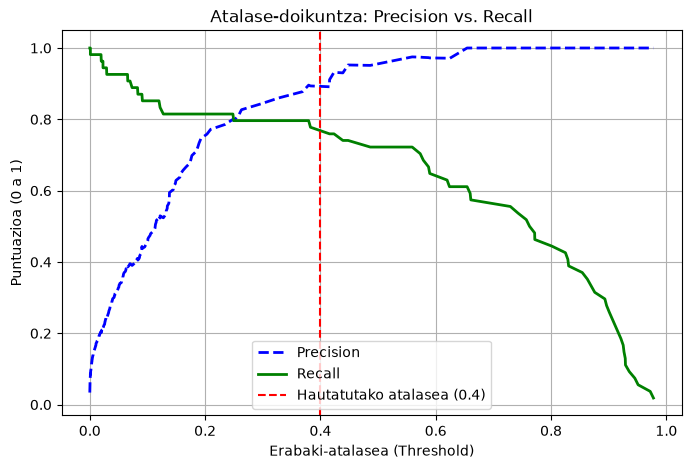

--- Sailkapen-txosten optimizatua (Atalasea 0.4) ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1546
           1       0.89      0.76      0.82        54

    accuracy                           0.99      1600
   macro avg       0.94      0.88      0.91      1600
weighted avg       0.99      0.99      0.99      1600



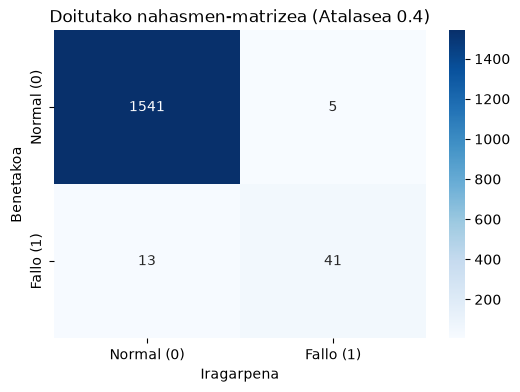

In [13]:
# 1. Lortu ereduaren hutsegite-probabilitateak
y_prob = model.predict_proba(X_val)[:, 1]

# ==========================================================
# LEHEN GRAFIKOA: Zehaztasuna vs. Gogoratzea (Gurutzatzen diren lerroak)
# ==========================================================
precisions, recalls, thresholds = precision_recall_curve(y_val, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(
    thresholds, recalls[:-1], "g-", label="Recall", linewidth=2
)

# Marra bertikal gorri eten bat, hautatutako atalasean (0,35)
umbral_optimo = 0.40
plt.axvline(
    x=umbral_optimo,
    color="red",
    linestyle="--",
    label=f"Hautatutako atalasea ({umbral_optimo})",
)

plt.xlabel("Erabaki-atalasea (Threshold)")
plt.ylabel("Puntuazioa (0 a 1)")
plt.title("Atalase-doikuntza: Precision vs. Recall")
plt.legend()
plt.grid(True)
plt.show()

# ==========================================================
# BIGARREN GRAFIKOA: Doitutako nahasmen-matrizea
# ==========================================================
# Atalase berria aplikatu
y_pred_ajustado = (y_prob >= umbral_optimo).astype(int)

print(f"--- Sailkapen-txosten optimizatua (Atalasea {umbral_optimo}) ---")
print(classification_report(y_val, y_pred_ajustado))

# Nahasmen-matrizea irudikatu
cm_ajustada = confusion_matrix(y_val, y_pred_ajustado)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_ajustada,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal (0)", "Fallo (1)"],
    yticklabels=["Normal (0)", "Fallo (1)"],
)
plt.xlabel("Iragarpena")
plt.ylabel("Benetakoa")
plt.title(f"Doitutako nahasmen-matrizea (Atalasea {umbral_optimo})")
plt.show()

## 7. Eredua Gorde

Scoring-api-k `/models/cnc_failure_model.pkl` bilatu behar du.

In [14]:
# Eredua gordetzeko direktorioa sortu, beharrezkoa bada
os.makedirs("../models", exist_ok=True)

# Entrenatutako eredua fitxategi batean gorde
joblib.dump(model, "../models/cnc_failure_model.pkl")

print("Eredua behar bezala gorde da: ../models/cnc_failure_model.pkl")

# Gordetako eredua kargatu dela egiaztatu
eredu_kargatua = joblib.load("../models/cnc_failure_model.pkl")

print("Gordetako eredua behar bezala kargatu da.")

Eredua behar bezala gorde da: ../models/cnc_failure_model.pkl
Gordetako eredua behar bezala kargatu da.
